### Pedro Domitti de Carvalho | RA: 21005320
### Vinicius Papa Batista | RA: 21004792

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Grouping Analysis
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans

In [2]:
df = pd.read_csv('../data/fruits.csv')

In [3]:
df.head()

,semana_mes,banana,laranja,maca
0,1,1000,1700,2400
1,2,1100,1200,1200
2,3,1500,1000,500
3,4,700,600,700
4,1,2000,3500,4700


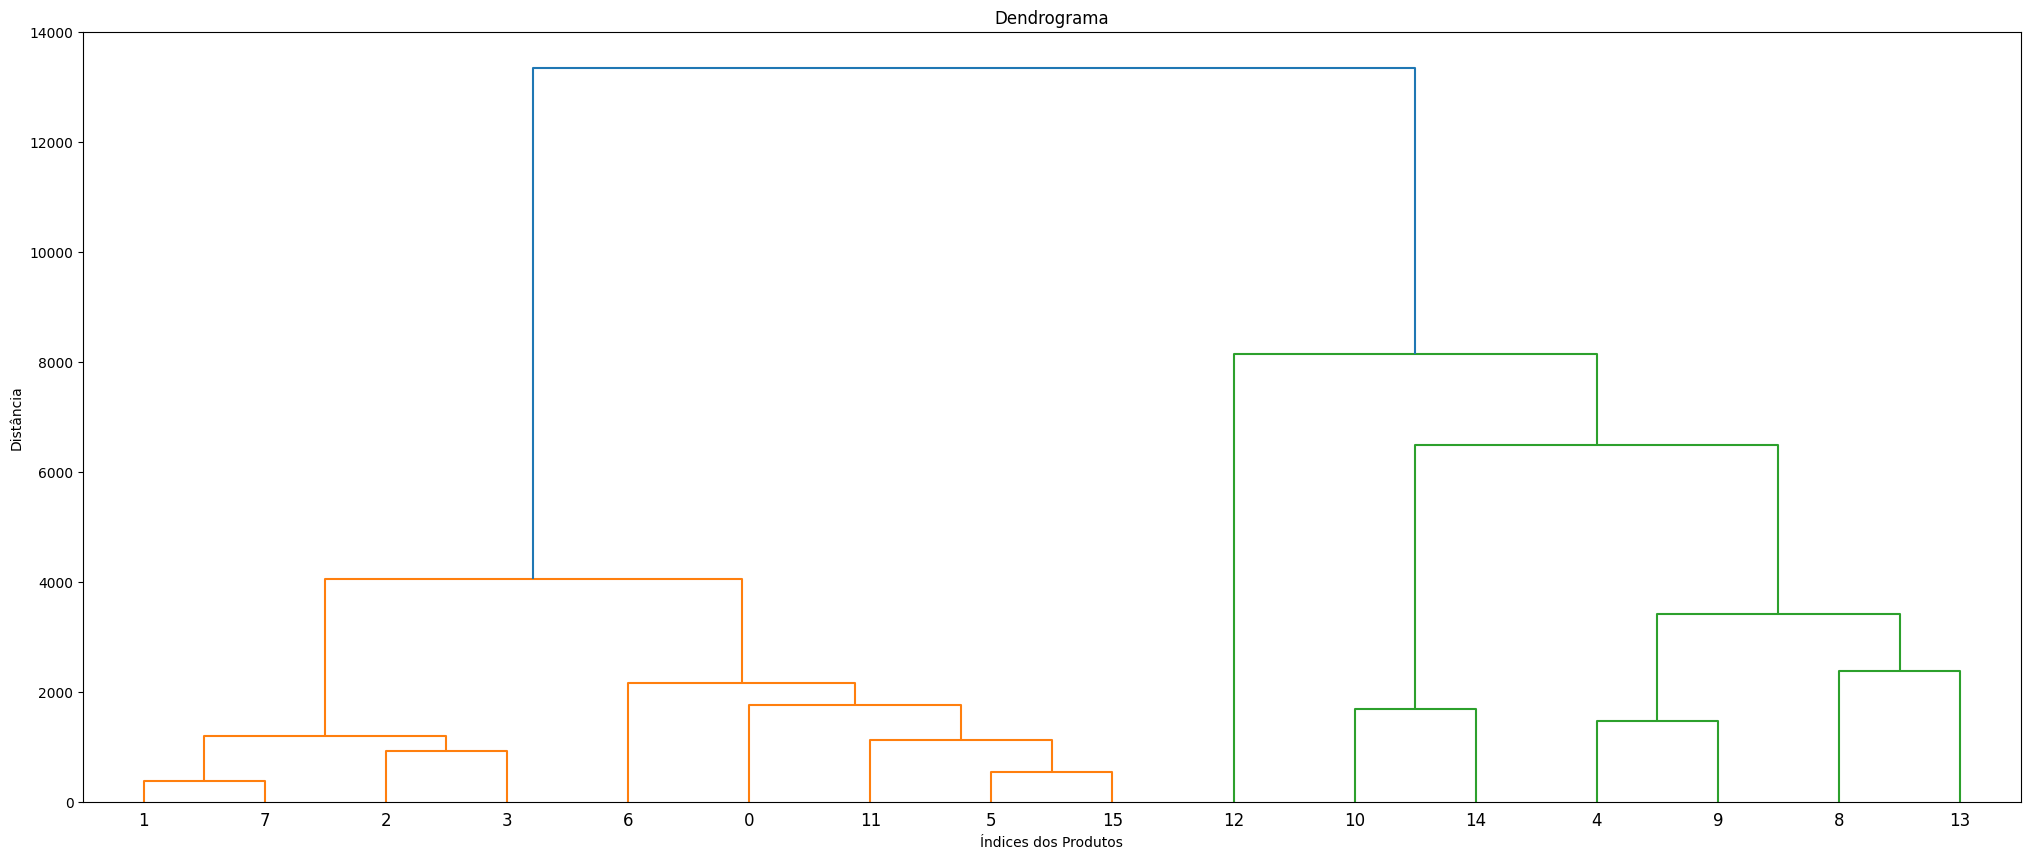

In [4]:
# Hierarchical Clustering (Dendrogram)
X = df
Z = linkage(X, 'ward')
plt.figure(figsize=(25, 10))
plt.title('Dendrograma')
plt.xlabel('Índices dos Produtos')
plt.ylabel('Distância')
dendrogram(Z)
plt.show()

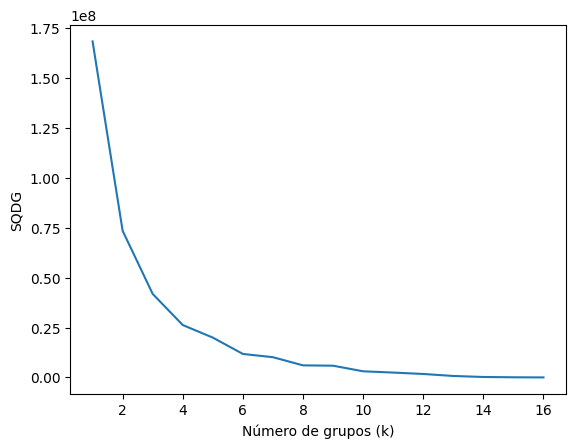

In [5]:
# SQDG
SQDG = {}

for k in range(1,17):
  kmeans=KMeans(n_clusters=k, max_iter=1000).fit(df)
  df['Cluster']=kmeans.labels_
  SQDG[k]= kmeans.inertia_  # Inertia: Sum of distances of samples to their closest cluster center

plt.figure
plt.plot(list(SQDG.keys()),list(SQDG.values()))
plt.xlabel('Número de grupos (k)')
plt.ylabel('SQDG');
plt.show()

In [6]:
# Non-Hierarchical Clustering (K-Means)
kmeans = KMeans(n_clusters=3, random_state=0).fit(X)
df['Cluster'] = kmeans.labels_

df.head()

,semana_mes,banana,laranja,maca,Cluster
0,1,1000,1700,2400,1
1,2,1100,1200,1200,1
2,3,1500,1000,500,1
3,4,700,600,700,1
4,1,2000,3500,4700,2


In [7]:
df.groupby('Cluster').mean()

df.groupby('Cluster').median()

,semana_mes,banana,laranja,maca
Cluster,,,,
0,1.0,3500.0,6000.0,8250.0
1,3.0,1500.0,1700.0,1400.0
2,2.0,4400.0,3500.0,4000.0


In [8]:
grupo0 = df.query('Cluster == 0').index
print(list(grupo0))
grupo1 = df.query('Cluster == 1').index
print(list(grupo1))
grupo2 = df.query('Cluster == 2').index
print(list(grupo2))

[8, 12]
[0, 1, 2, 3, 5, 6, 7, 11, 15]
[4, 9, 10, 13, 14]


Com base nas análises acima pergunta-se: Há indícios de recorrência do comportamento conjunto de vendas de banana, laranja e maçã em determinadas semanas?

- Resposta: Sim, há indícios de recorrência do comportamento conjunto de vendas de banana, laranja e maçã em determinadas semanas, pois a análise de correlação entre as vendas desses produtos mostrou que há uma correlação positiva entre as vendas de banana e laranja, e entre as vendas de banana e maçã. Além disso, a análise de sazonalidade mostrou que as vendas desses produtos apresentam um padrão de comportamento semanal, com picos de vendas em determinados dias da semana. Portanto, é possível que as vendas desses produtos estejam relacionadas e ocorram de forma recorrente em determinadas semanas.